# Operaciones de aprendizaje automático
## Maestría en Inteligencia Artificial Aplicada

### TC5061 | Proyecto MiBici: propuesta y base reproducible | Colaborativo

#### **Equipo:** 7
#### **Nombre:** Luis Arturo Sánchez Davila
#### **Matrícula:** A01840576

## Objetivo
Notebook de **exploración** del proyecto MiBici: carga y descripción del dataset de viajes ya consolidado en Parquet, análisis exploratorio de datos (EDA) y evidencia para las decisiones de limpieza que acordará el equipo.

La pregunta que me corresponde es la **P? (TIPO)**: <!-- TODO: pegar la pregunta de negocio asignada -->

La lógica que se reutilice se trasladará al módulo del proyecto; en este notebook se desarrolla y se documenta la evidencia que la justifica.

## Dataset
**Datos abiertos de MiBici** (sistema de bicicleta pública del Área Metropolitana de Guadalajara), en la versión **ya convertida a Parquet** en `0.01-fat-exploracion-inicial`.
- Archivos: `datos_abiertos_AAAA_MM.parquet`, uno por mes, en `data/external/`. El portal publica **CSV**, no Parquet; si los Parquet no existen, el notebook los genera a partir del CSV del portal (ver 1.1).
- Cada registro es un viaje: `viaje_id`, `usuario_id`, `genero`, `anio_de_nacimiento`, `inicio_del_viaje`, `fin_del_viaje`, `origen_id` y `destino_id`.
- Fuente original: [Datos abiertos de MiBici](https://mibici.net/es/datos-abiertos/)
- Rango analizado: **enero de 2020 a septiembre de 2026**, acordado por el equipo para homologar el EDA. El portal ya no publica 2023-04 ni 2023-05 (ver `0.02-dsh-exploracion-carga`).

## Nota de reproducibilidad
El notebook se ejecuta desde la carpeta `notebooks/` con el entorno descrito en el README. Los Parquet de `data/external/` y los CSV de `data/raw/` no se versionan en Git. La primera ejecución descarga los CSV faltantes del portal y genera los Parquet; las siguientes reutilizan los que ya existen.

In [1]:
# Importación de librerías y registro de versiones (evidencia de reproducibilidad)
from pathlib import Path
import re
import sys
import time
from urllib.parse import urljoin

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow
import requests
import seaborn as sns

print("Python      :", sys.version.split()[0])
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("pyarrow     :", pyarrow.__version__)
print("requests    :", requests.__version__)
print("matplotlib  :", matplotlib.__version__)
print("seaborn     :", sns.__version__)

Python      : 3.11.9
pandas      : 3.0.5
numpy       : 1.26.4
pyarrow     : 25.0.1
requests    : 2.34.2
matplotlib  : 3.11.2
seaborn     : 0.13.2


## Configuración global

Todos los valores que se usan en más de una celda se definen una sola vez aquí:
- **Rutas:** CSV crudos del portal (`data/raw/`), Parquet mensuales (`data/external/`) datos intermedios (`data/interim/`) y datos procesados (`data/processed/`).
- **Fuente y rango:** URL del portal, meses inicial y final (inclusivos), meses que el portal ya no publica y encabezados HTTP.
- **Random seed:** para que cualquier muestreo sea reproducible.
- **Opciones de visualización:** pandas muestra todas las columnas.
- **Colores:** paleta Okabe-Ito, apta para daltonismo, referida por nombre.

In [2]:
# Rutas del proyecto (el notebook se ejecuta desde notebooks/)
RUTA_PROYECTO = Path.cwd().parent
RUTA_VIAJES_CRUDOS = RUTA_PROYECTO / "data" / "raw" / "viajes"
RUTA_ESTACIONES_CRUDAS = RUTA_PROYECTO / "data" / "raw" / "estaciones"
RUTA_PARQUET = RUTA_PROYECTO / "data" / "external"
RUTA_INTERMEDIOS = RUTA_PROYECTO / "data" / "interim"
RUTA_PROCESADOS = RUTA_PROYECTO / "data" / "processed"

# Rango de meses a analizar (inclusivos)
MES_INICIO = "2020-01"
MES_FIN = "2026-09"

# Fuente de los datos
URL_PORTAL = "https://mibici.net/es/datos-abiertos/"

# El portal dejó de publicar estos meses; solo estos huecos se aceptan (ver 0.02-dsh-exploracion-carga)
MESES_SIN_PUBLICAR = ["2023-04", "2023-05"]

# El portal rechaza (error 406) las peticiones con el User-Agent por defecto de requests
ENCABEZADOS_HTTP = {"User-Agent": "Mozilla/5.0 (proyecto academico MLOps TC5061)",
                    "Accept": "text/html,text/csv,*/*",
}

SEMILLA = 42

# Opciones de visualización de pandas
pd.set_option("display.max_columns", None)   # mostrar todas las columnas
pd.set_option("display.max_colwidth", None)  # no recortar textos largos

# Paleta Okabe-Ito (apta para daltonismo)
AZUL = "#0072B2"
NARANJA = "#E69F00"
VERDE = "#009E73"

RUTA_VIAJES_CRUDOS.mkdir(parents=True, exist_ok=True)
RUTA_PARQUET.mkdir(parents=True, exist_ok=True)
RUTA_INTERMEDIOS.mkdir(parents=True, exist_ok=True)
RUTA_PROCESADOS.mkdir(parents=True, exist_ok=True)

## Paso 1: Carga y descripción del dataset

En este paso se obtienen los Parquet mensuales, se leen y se valida que la carga sea completa antes de describir el dataset. Cualquier diferencia se documenta como hallazgo y se resuelve con evidencia, no con supuestos.


### 1.1 Obtención de los Parquet

El portal solo publica **CSV**. Los Parquet de `data/external/` son una conversión local, así que para cada mes del rango:
1. Si ya existe `datos_abiertos_AAAA_MM.parquet`, se reutiliza.
2. Si no, se toma el CSV de `data/raw/viajes/`; si tampoco existe, se descarga del portal (los enlaces se leen de la página porque cada archivo vive en una carpeta con identificador distinto).
3. El CSV se convierte a Parquet con nombres de columna en minúsculas sin acentos (`anio_de_nacimiento`), fechas como `datetime` y enteros con tipo que admite nulos.

La codificación (UTF-8 o latin-1) y el formato de fecha (`AAAA-MM-DD hh:mm:ss` o `DD/MM/AAAA hh:mm`) varían entre archivos; se detectan por archivo y, si un valor no se convierte, el notebook se detiene en lugar de dejar fechas nulas sin avisar.

In [3]:
# Obtención de los Parquet faltantes: descarga del CSV y conversión
COLUMNAS_PARQUET = ["viaje_id", "usuario_id", "genero", "anio_de_nacimiento",
                    "inicio_del_viaje", "fin_del_viaje", "origen_id", "destino_id"]
TIPOS_ENTEROS = {"viaje_id": "Int64", "usuario_id": "Int64", "anio_de_nacimiento": "Int16",
                 "origen_id": "Int32", "destino_id": "Int32"}
FORMATOS_FECHA = ["%Y-%m-%d %H:%M:%S", "%d/%m/%Y %H:%M"]


def nombre_parquet(periodo):
    """Regresa el nombre del Parquet de un periodo 'AAAA-MM'."""
    return f"datos_abiertos_{periodo.replace('-', '_')}.parquet"


def enlaces_del_portal():
    """Regresa {periodo: URL} de los CSV de viajes publicados en el portal."""
    respuesta = requests.get(URL_PORTAL, headers=ENCABEZADOS_HTTP, timeout=30)
    respuesta.raise_for_status()
    enlaces = {}
    for href in re.findall(r"href=['\"]([^'\"]+)['\"]", respuesta.text):
        coincidencia = re.search(r"datos_abiertos_(\d{4})_(\d{2})\.csv", href)
        if coincidencia:
            enlaces[f"{coincidencia[1]}-{coincidencia[2]}"] = urljoin(URL_PORTAL, href)
    return enlaces


def csv_a_parquet(ruta_csv, ruta_parquet):
    """Convierte un CSV de viajes a Parquet con columnas, fechas y tipos normalizados."""
    contenido = ruta_csv.read_bytes()
    try:
        contenido.decode("utf-8")
        codificacion = "utf-8"
    except UnicodeDecodeError:
        codificacion = "latin-1"  # decodifica cualquier byte; se usa como último recurso

    viajes = pd.read_csv(ruta_csv, encoding=codificacion, dtype=str)
    if viajes.shape[1] != len(COLUMNAS_PARQUET):
        raise ValueError(f"{ruta_csv.name} tiene {viajes.shape[1]} columnas, se esperaban {len(COLUMNAS_PARQUET)}")
    viajes.columns = COLUMNAS_PARQUET  # por posición: el nombre de 'Año_de_nacimiento' llega corrupto en algunos archivos

    for columna in ("inicio_del_viaje", "fin_del_viaje"):
        con_dato = viajes[columna].notna().sum()
        for formato in FORMATOS_FECHA:
            convertida = pd.to_datetime(viajes[columna], format=formato, errors="coerce")
            if convertida.notna().sum() == con_dato:
                viajes[columna] = convertida
                break
        else:
            raise ValueError(f"{ruta_csv.name}: {columna} tiene fechas que no coinciden con {FORMATOS_FECHA}")
    for columna, tipo in TIPOS_ENTEROS.items():
        viajes[columna] = pd.to_numeric(viajes[columna], errors="coerce").astype(tipo)
    viajes["genero"] = viajes["genero"].astype("category")

    viajes.to_parquet(ruta_parquet, index=False)
    return len(viajes)


# Meses del rango cuyo Parquet no existe y que el portal sí debería publicar
periodos = [str(p) for p in pd.period_range(MES_INICIO, MES_FIN, freq="M")]
pendientes = [p for p in periodos
              if not (RUTA_PARQUET / nombre_parquet(p)).exists() and p not in MESES_SIN_PUBLICAR]
print("Meses del rango:", len(periodos), "| Parquet por generar:", len(pendientes))

if pendientes:
    enlaces = enlaces_del_portal()
    sin_enlace = [p for p in pendientes
                  if p not in enlaces and not (RUTA_VIAJES_CRUDOS / f"datos_abiertos_{p.replace('-', '_')}.csv").exists()]
    if sin_enlace:
        raise ValueError(f"Meses sin Parquet, sin CSV y sin enlace en el portal: {sin_enlace}")

    descargados = 0
    for periodo in pendientes:
        ruta_csv = RUTA_VIAJES_CRUDOS / f"datos_abiertos_{periodo.replace('-', '_')}.csv"
        if not ruta_csv.exists():
            respuesta = requests.get(enlaces[periodo], headers=ENCABEZADOS_HTTP, timeout=60)
            respuesta.raise_for_status()
            ruta_csv.write_bytes(respuesta.content)
            descargados += 1
            time.sleep(1)  # pausa entre descargas para no saturar el portal
        registros = csv_a_parquet(ruta_csv, RUTA_PARQUET / nombre_parquet(periodo))
        print(f"{periodo}: {registros} registros")
    print("CSV descargados en esta ejecución:", descargados)

Meses del rango: 81 | Parquet por generar: 0


**Observaciones de la obtención:**
- **Origen:** en la primera ejecución (15-oct-2026) no existía ningún Parquet en `data/external/`; los 79 se generaron a partir de los CSV de `data/raw/viajes/`. En las siguientes ejecuciones se reutilizan.
- **Descargas:** 0 archivos. Los 79 CSV ya estaban en `data/raw/` desde la ejecución de `0.02-dsh-exploracion-carga`; si faltara alguno, se descargaría del portal.
- **Meses sin datos:** solo 2023-04 y 2023-05, los dos ya registrados en `MESES_SIN_PUBLICAR`; cualquier otro hueco detendría la celda.
- **Limitación:** la conversión replica la de `0.01-fat-exploracion-inicial` (nombres en minúsculas sin acentos, fechas como `datetime` y enteros que admiten nulos), pero esa conversión no está versionada; el esquema se infirió de sus resultados y debe confirmarse con el equipo.

In [4]:
# Lectura y unión de los Parquet mensuales dentro del rango
PATRON_ARCHIVO = re.compile(r"datos_abiertos_(\d{4})_(\d{2})\.parquet$")

archivos = []
for ruta in sorted(RUTA_PARQUET.glob("datos_abiertos_*.parquet")):
    coincidencia = PATRON_ARCHIVO.search(ruta.name)
    periodo = f"{coincidencia.group(1)}-{coincidencia.group(2)}" if coincidencia else None
    if periodo and MES_INICIO <= periodo <= MES_FIN:
        archivos.append((periodo, ruta))

if not archivos:
    raise FileNotFoundError(f"No hay Parquet en {RUTA_PARQUET}; ejecutar antes la celda 1.1")

viajes = pd.concat(
    [pd.read_parquet(ruta).assign(periodo_archivo=periodo) for periodo, ruta in archivos],
    ignore_index=True,
)

# Se convierte a category después de unir: es una cadena repetida millones de veces
viajes["periodo_archivo"] = viajes["periodo_archivo"].astype("category")

print("Archivos leídos:", len(archivos))
print(f"Registros      : {len(viajes):,}")
print("Columnas       :", viajes.shape[1])

Archivos leídos: 79
Registros      : 26,389,162
Columnas       : 9


**Observaciones de la lectura:**
- **Archivos:** se leyeron 79 Parquet de los 81 meses del rango; faltan 2023-04 y 2023-05.
- **Registros:** 26,389,162 viajes. El mes con menos viajes es 2020-04 (129,276) y el de más, 2026-09 (490,056).
- **Contraste con 0.02:** el total coincide exactamente con los 26,389,162 registros del inventario de `0.02`; la conversión no perdió ni duplicó ningún viaje.

### 1.3 Descripción del dataset

Se revisan los tipos, los nulos y el rango de fechas para saber qué columnas requieren limpieza.

In [5]:
# Columnas, tipos, valores no nulos y memoria
viajes.info(show_counts=True, memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 26389162 entries, 0 to 26389161
Data columns (total 9 columns):
 #   Column              Non-Null Count     Dtype         
---  ------              --------------     -----         
 0   viaje_id            26389162 non-null  Int64         
 1   usuario_id          26389162 non-null  Int64         
 2   genero              26253930 non-null  category      
 3   anio_de_nacimiento  26355366 non-null  Int16         
 4   inicio_del_viaje    26389162 non-null  datetime64[ns]
 5   fin_del_viaje       26389162 non-null  datetime64[ns]
 6   origen_id           26389162 non-null  Int32         
 7   destino_id          26389162 non-null  Int32         
 8   periodo_archivo     26389162 non-null  category      
dtypes: Int16(1), Int32(2), Int64(2), category(2), datetime64[ns](2)
memory usage: 1.2 GB


In [6]:
# Nulos y valores distintos por columna
resumen = pd.DataFrame({
    "nulos": viajes.isna().sum(),
    "% nulos": (viajes.isna().mean() * 100).round(2),
    "distintos": viajes.nunique(),
})
resumen

,nulos,% nulos,distintos
viaje_id,0,0.00,26388404
usuario_id,0,0.00,81115
genero,135232,0.51,2
anio_de_nacimiento,33796,0.13,87
inicio_del_viaje,0,0.00,22616495
fin_del_viaje,0,0.00,22569727
origen_id,0,0.00,475
destino_id,0,0.00,475
periodo_archivo,0,0.00,79


In [7]:
# Rango de fechas de inicio y fin de los viajes
print("Inicio:", viajes["inicio_del_viaje"].min(), "->", viajes["inicio_del_viaje"].max())
print("Fin   :", viajes["fin_del_viaje"].min(), "->", viajes["fin_del_viaje"].max())

Inicio: 2020-01-01 06:02:20 -> 2026-09-30 23:59:48
Fin   : 2020-01-01 06:05:38 -> 2026-10-01 00:14:52


**Observaciones de la descripción del dataset:**
- **Estructura:** 26,389,162 registros y 9 columnas (las 8 originales más `periodo_archivo`). `genero` y `periodo_archivo` son categorías; los identificadores, el año de nacimiento y las estaciones son enteros que admiten nulos.
- **Nulos:** solo `genero` (135,232, 0.51 %) y `anio_de_nacimiento` (33,796, 0.13 %) tienen valores nulos; las otras siete columnas están completas, incluidas las fechas.
- **Identificadores repetidos:** 26,388,404 `viaje_id` distintos para 26,389,162 registros, es decir, 758 repetidos; en 2.2 se confirma que son filas idénticas.
- **Fechas:** los viajes inician entre 2020-01-01 06:02:20 y 2026-09-30 23:59:48; el fin llega hasta 2026-10-01 00:14:52, porque los viajes iniciados al final de septiembre terminan en octubre.
- **Limitación:** el rango de fechas confirma el periodo pero no la continuidad: los huecos mensuales se ven en la sección 2.3.

## Paso 2: Análisis exploratorio de datos (EDA)

En este paso se explora el dataset unido **sin modificarlo**: cada hallazgo se cuantifica y se documenta para que el equipo acuerde su tratamiento en la limpieza. Las preguntas que guían el EDA salen del ML Canvas (`references/ml-canvas.md`):
- **Calidad:** ¿qué registros no se pueden usar tal cual (duplicados, duraciones, estaciones sin nomenclatura)?
- **Tiempo:** ¿cómo evoluciona el volumen y qué patrones horarios y semanales hay? Es la base de P1.
- **Estaciones:** ¿qué tan concentrada está la demanda y qué estaciones acumulan o pierden bicicletas? Es la base de P2 y P3.

Solo se muestran **agregados**; no se imprimen filas con `usuario_id`.

### 2.1 Preparación

Se cargan la nomenclatura de estaciones y tres variables derivadas: duración en minutos, hora del día y día de la semana (0 = lunes).

In [8]:
# Variables derivadas para el EDA (las columnas originales no cambian)
viajes["duracion_min"] = (viajes["fin_del_viaje"] - viajes["inicio_del_viaje"]).dt.total_seconds() / 60
viajes["hora"] = viajes["inicio_del_viaje"].dt.hour.astype("int8")
viajes["dia_semana"] = viajes["inicio_del_viaje"].dt.dayofweek.astype("int8")

# Nomenclatura de estaciones (UTF-8 o latin-1, igual que los viajes)
ruta_nomenclatura = sorted(RUTA_ESTACIONES_CRUDAS.glob("nomenclatura_*.csv"))[-1]
try:
    nomenclatura = pd.read_csv(ruta_nomenclatura, encoding="utf-8")
except UnicodeDecodeError:
    nomenclatura = pd.read_csv(ruta_nomenclatura, encoding="latin-1")

print("Nomenclatura:", ruta_nomenclatura.name, "|", len(nomenclatura), "estaciones")
print(f"Memoria del DataFrame: {viajes.memory_usage(deep=True).sum() / 1024**3:.1f} GB")
nomenclatura.describe().T

Nomenclatura: nomenclatura_2026_09.csv | 484 estaciones
Memoria del DataFrame: 1.5 GB


,count,mean,std,min,25%,50%,75%,max
id,484.0,254.758264,148.293765,2.000000,129.750000,252.000000,379.250000,519.000000
latitude,484.0,20.678520,0.022032,20.636130,20.665077,20.674390,20.688609,20.739523
longitude,484.0,-103.361871,0.031626,-103.433215,-103.384164,-103.362443,-103.339320,-103.297112
dpcapacity,484.0,16.882231,4.126942,0.000000,15.000000,15.000000,19.000000,39.000000


### 2.2 Calidad de los datos

Antes de buscar patrones se mide qué parte del dataset no es utilizable tal cual. Se revisan cuatro cosas:
- **Duplicados:** un mismo `viaje_id` repetido, y si la fila completa también lo está (duplicado exacto) o difiere (conflicto).
- **Duración:** negativa, cero y extrema. Un viaje de duración cero suele ser un desbloqueo fallido; uno de más de 24 horas, una bicicleta no devuelta.
- **Año de nacimiento:** solo se cuentan valores imposibles; la variable no se usará en el modelado.
- **Estaciones sin nomenclatura:** sin capacidad ni ubicación no se pueden usar en P2 ni P3.

In [9]:
# Duplicados: identificadores repetidos y filas completas repetidas
COLUMNAS_ORIGINALES = ["viaje_id", "usuario_id", "genero", "anio_de_nacimiento",
                       "inicio_del_viaje", "fin_del_viaje", "origen_id", "destino_id"]
ids_repetidos = int(viajes["viaje_id"].duplicated().sum())
filas_repetidas = int(viajes.duplicated(subset=COLUMNAS_ORIGINALES).sum())

print(f"Registros con viaje_id ya visto      : {ids_repetidos:,}")
print(f"Filas completas repetidas            : {filas_repetidas:,}")
print(f"Ids repetidos con datos distintos    : {ids_repetidos - filas_repetidas:,}")

Registros con viaje_id ya visto      : 758
Filas completas repetidas            : 758
Ids repetidos con datos distintos    : 0


In [10]:
# Duración del viaje en minutos: anomalías y percentiles
duracion = viajes["duracion_min"]
negativas = int((duracion < 0).sum())
ceros = int((duracion == 0).sum())
mas_de_24h = int((duracion > 24 * 60).sum())

print(f"Duración negativa : {negativas:,}")
print(f"Duración cero     : {ceros:,} ({ceros / len(viajes):.2%})")
print(f"Más de 24 horas   : {mas_de_24h:,}")
print(f"Máxima            : {duracion.max() / 60:.1f} horas")
duracion.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99, .999]).round(2).to_frame("duracion_min")

Duración negativa : 0
Duración cero     : 53,581 (0.20%)
Más de 24 horas   : 157
Máxima            : 469.2 horas


,duracion_min
count,26389162.00
mean,11.01
std,15.60
min,0.00
1%,0.20
5%,2.02
25%,5.72
50%,9.45
75%,14.77
95%,24.15


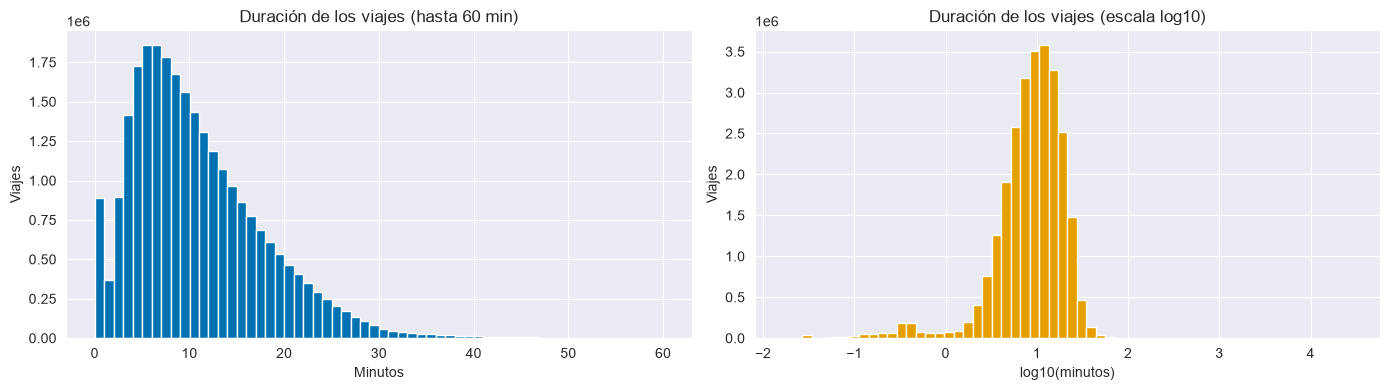

In [11]:
# Distribución de la duración: viajes de hasta 60 minutos y escala logarítmica de todos los positivos
fig, ejes = plt.subplots(1, 2, figsize=(14, 4))

duracion[(duracion > 0) & (duracion <= 60)].plot.hist(bins=60, ax=ejes[0], color=AZUL)
ejes[0].set_title("Duración de los viajes (hasta 60 min)")
ejes[0].set_xlabel("Minutos")
ejes[0].set_ylabel("Viajes")

np.log10(duracion[duracion > 0]).plot.hist(bins=60, ax=ejes[1], color=NARANJA)
ejes[1].set_title("Duración de los viajes (escala log10)")
ejes[1].set_xlabel("log10(minutos)")
ejes[1].set_ylabel("Viajes")

plt.tight_layout()
plt.show()

In [12]:
# Año de nacimiento: solo se cuentan valores imposibles (agregados, sin filas individuales)
anio = viajes["anio_de_nacimiento"]
antes_1900 = int((anio < 1900).sum())
despues_2010 = int((anio > 2010).sum())
print(f"Anterior a 1900 : {antes_1900:,}")
print(f"Posterior a 2010: {despues_2010:,}")
print(f"Plausible (1920 a 2010): {anio.between(1920, 2010).sum() / anio.notna().sum():.2%} de los registros con dato")

Anterior a 1900 : 1,255
Posterior a 2010: 2,093
Plausible (1920 a 2010): 99.98% de los registros con dato


In [13]:
# Estaciones de los viajes que no están en la nomenclatura vigente
ids_nomenclatura = set(nomenclatura["id"])
ids_usados = set(viajes["origen_id"].dropna().unique()) | set(viajes["destino_id"].dropna().unique())
ids_sin_nomenclatura = sorted(ids_usados - ids_nomenclatura)

viajes_afectados = int((~viajes["origen_id"].isin(ids_nomenclatura) | ~viajes["destino_id"].isin(ids_nomenclatura)).sum())
sin_capacidad = int((nomenclatura["dpcapacity"] == 0).sum())

print("Estaciones con viajes         :", len(ids_usados))
print("Estaciones en la nomenclatura :", len(ids_nomenclatura))
print("Ids sin nomenclatura          :", ids_sin_nomenclatura)
print(f"Viajes afectados              : {viajes_afectados:,} ({viajes_afectados / len(viajes):.3%})")
print("Estaciones con capacidad 0    :", sin_capacidad)

Estaciones con viajes         : 475
Estaciones en la nomenclatura : 484
Ids sin nomenclatura          : [124, 405, 407]
Viajes afectados              : 3,961 (0.015%)
Estaciones con capacidad 0    : 4


In [14]:
# Resumen de calidad: registros afectados por hallazgo
total = len(viajes)
resumen_calidad = pd.DataFrame({
    "hallazgo": ["Filas completas repetidas", "Duración cero", "Duración mayor a 24 h",
                 "Año de nacimiento anterior a 1900", "Año de nacimiento posterior a 2010",
                 "Origen o destino sin nomenclatura", "Género nulo", "Año de nacimiento nulo"],
    "registros": [filas_repetidas, ceros, mas_de_24h, antes_1900, despues_2010, viajes_afectados,
                  int(viajes["genero"].isna().sum()), int(viajes["anio_de_nacimiento"].isna().sum())],
})
resumen_calidad["% del total"] = (resumen_calidad["registros"] / total * 100).round(3)
resumen_calidad

,hallazgo,registros,% del total
0,Filas completas repetidas,758,0.003
1,Duración cero,53581,0.203
2,Duración mayor a 24 h,157,0.001
3,Año de nacimiento anterior a 1900,1255,0.005
4,Año de nacimiento posterior a 2010,2093,0.008
5,Origen o destino sin nomenclatura,3961,0.015
6,Género nulo,135232,0.512
7,Año de nacimiento nulo,33796,0.128


**Observaciones de la calidad de los datos:**
- **Duplicados:** 758 registros repiten un `viaje_id` ya visto y los 758 son filas idénticas en todas las columnas; no hay identificadores repetidos con datos distintos. Eliminarlos no implica elegir entre versiones en conflicto.
- **Duración:** ninguna es negativa. 53,581 viajes (0.20 %) duran cero minutos y 157 duran más de 24 horas, con un máximo de 469.2 horas. La mediana es 9.45 min y el 99 % dura 32.82 min o menos; el 99.9 % no pasa de 58.78 min. El volumen extremo es mínimo, pero distorsiona la media (11.01 min) y la desviación (15.60 min) por una cola muy larga.
- **Año de nacimiento:** 1,255 valores anteriores a 1900 y 2,093 posteriores a 2010 (0.013 % del total entre ambos); el 99.98 % de los registros con dato cae entre 1920 y 2010. La variable no se usará en el modelado, por lo que el hallazgo solo importa si se describe a los usuarios.
- **Estaciones:** 475 estaciones tienen viajes y la nomenclatura vigente tiene 484. Tres identificadores (124, 405 y 407) aparecen en viajes y no en la nomenclatura: 3,961 viajes (0.015 %). Cuatro estaciones de la nomenclatura tienen capacidad 0.
- **Impacto:** ningún hallazgo supera el 0.52 % del total; el más grande son los nulos de `genero` (0.51 %). Los que obligarían a excluir registros (duplicados, duración cero o extrema y estaciones sin nomenclatura) suman como máximo 58,457 registros (0.22 %), sin descontar traslapes. La limpieza no compromete el tamaño del dataset.

### 2.3 Volumen de viajes en el tiempo

La serie mensual muestra la tendencia, el efecto de la pandemia y el hueco de 2023-04 y 2023-05. Es el primer insumo para decidir si P1 necesita un indicador de periodo y cómo tratar los rezagos que cruzan el hueco.

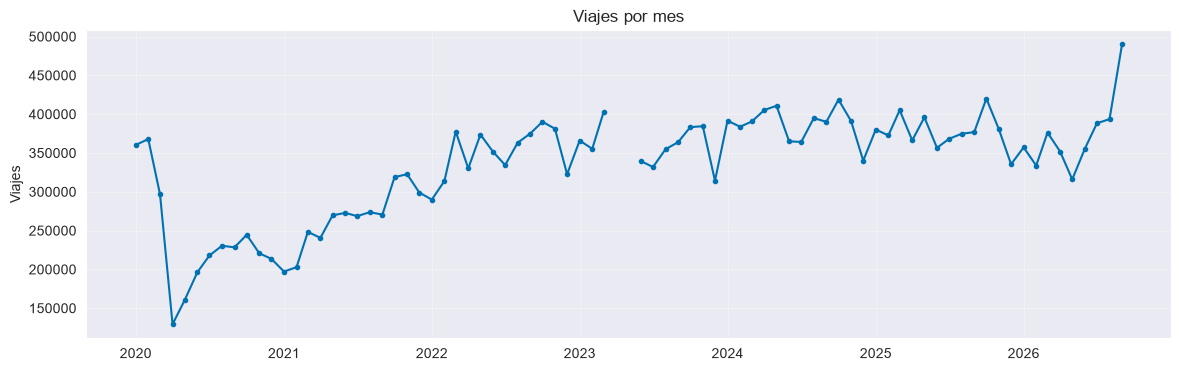

Mes con menos viajes: 2020-04 (129,276)
Mes con más viajes  : 2026-09 (490,056)
Mediana mensual     : 356,611
Meses sin dato      : ['2023-04', '2023-05']


In [15]:
# Viajes por mes sobre el calendario completo del rango (los meses sin archivo quedan como NaN)
mensual = viajes.groupby("periodo_archivo", observed=True).size()
mensual.index = pd.PeriodIndex(mensual.index.astype(str), freq="M")
mensual = mensual.reindex(pd.period_range(MES_INICIO, MES_FIN, freq="M"))

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(mensual.index.to_timestamp(), mensual.values, marker="o", markersize=3, color=AZUL)
ax.set_title("Viajes por mes")
ax.set_ylabel("Viajes")
ax.grid(alpha=0.3)
plt.show()

print("Mes con menos viajes:", mensual.idxmin(), f"({mensual.min():,.0f})")
print("Mes con más viajes  :", mensual.idxmax(), f"({mensual.max():,.0f})")
print(f"Mediana mensual     : {mensual.median():,.0f}")
print("Meses sin dato      :", [str(p) for p in mensual[mensual.isna()].index])

In [16]:
# Viajes por año: total, promedio por mes con dato y variación contra el año anterior
anual = mensual.groupby(mensual.index.year).agg(viajes="sum", meses_con_dato="count")
anual["promedio_mensual"] = (anual["viajes"] / anual["meses_con_dato"]).round(0)
anual["variacion_vs_anio_previo_%"] = (anual["promedio_mensual"].pct_change() * 100).round(1)
anual

,viajes,meses_con_dato,promedio_mensual,variacion_vs_anio_previo_%
2020,2866072.0,12,238839.0,NaN
2021,3184410.0,12,265368.0,11.1
2022,4202942.0,12,350245.0,32.0
2023,3595720.0,10,359572.0,2.7
2024,4645921.0,12,387160.0,7.7
2025,4532032.0,12,377669.0,-2.5
2026,3362065.0,9,373563.0,-1.1


**Observaciones del volumen en el tiempo:**
- **Tendencia:** el promedio mensual crece de 238,839 viajes en 2020 a 387,160 en 2024 y se estabiliza: 377,669 en 2025 (−2.5 %) y 373,563 en 2026 (−1.1 %, con 9 meses). Después de 2024 el sistema muestra una meseta, no un crecimiento.
- **Pandemia:** el volumen cae de 367,864 viajes en febrero de 2020 a 129,276 en abril (−64.9 %). El primer mes que supera el nivel de febrero de 2020 es marzo de 2022 (377,505), dos años después. Un modelo entrenado con 2020 aprende un régimen que no se repite; se justifica un indicador de periodo o excluir 2020 de los ajustes.
- **Hueco 2023-04 y 2023-05:** 2 de los 81 meses del rango (2.5 %) no tienen datos. La serie pasa de 402,460 viajes en marzo a 339,628 en junio sin ningún punto intermedio, por lo que los rezagos y las ventanas que cruzan el hueco no se pueden calcular. No se imputará sin acuerdo del equipo.
- **Estacionalidad:** hay caídas recurrentes en diciembre (por ejemplo, 299,005 en 2021-12 y 314,164 en 2023-12), consistentes con el periodo vacacional. El mes del año es una variable relevante para P1.
- **Último mes:** 2026-09 (490,056) es el máximo de toda la serie: 24.5 % más que agosto (393,524) y 30.1 % más que septiembre de 2025 (376,789). El EDA no explica la causa; hay que verificar que sea un valor real y no una carga atípica antes de que forme parte del conjunto de prueba.

### 2.4 Patrones por hora y día de la semana

Se mide qué proporción de los viajes ocurre en cada hora y día. Un perfil con dos picos (mañana y tarde) en días laborales indica uso para ir al trabajo; es la señal que justifica incluir `hora`, `dia_semana` y festivos como features de P1 y P2.

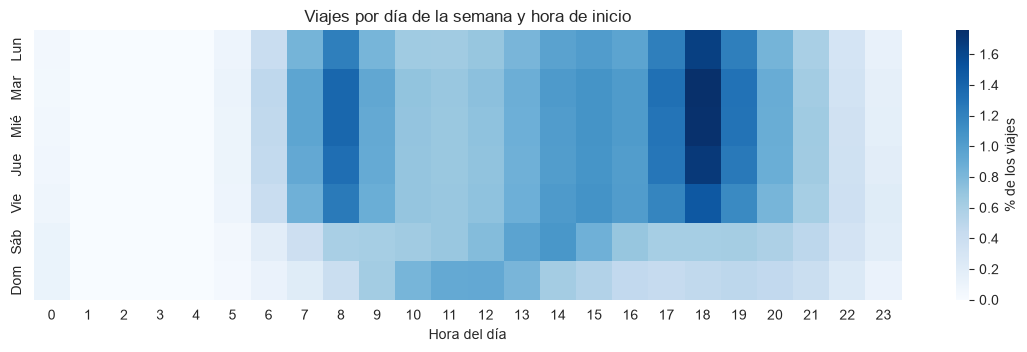

In [17]:
# Proporción de viajes por día de la semana y hora de inicio
DIAS = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
conteo = viajes.groupby(["dia_semana", "hora"], observed=True).size().unstack(fill_value=0)
proporcion = conteo / conteo.to_numpy().sum() * 100

fig, ax = plt.subplots(figsize=(14, 3.5))
sns.heatmap(proporcion, cmap="Blues", ax=ax, yticklabels=DIAS, cbar_kws={"label": "% de los viajes"})
ax.set_title("Viajes por día de la semana y hora de inicio")
ax.set_xlabel("Hora del día")
ax.set_ylabel("")
plt.show()

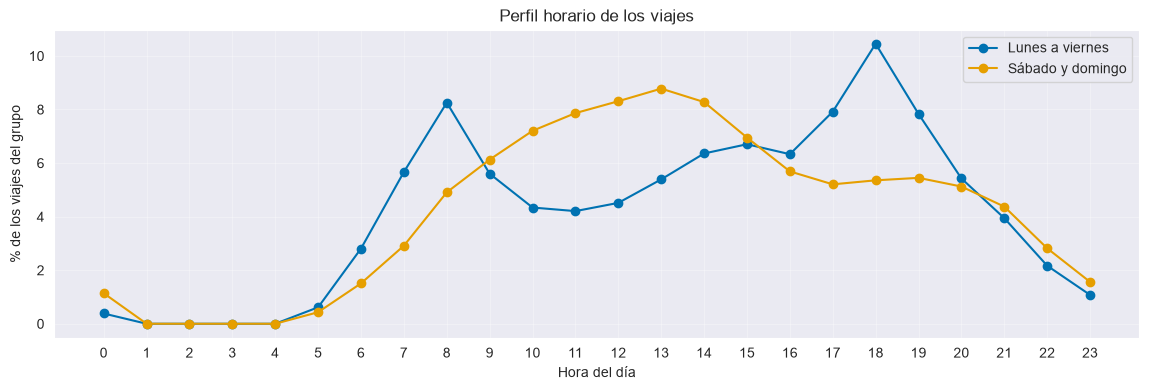

Horas pico lunes a viernes: [18, 8, 17]
Horas pico fin de semana  : [13, 12, 14]
Viajes en fin de semana   : 20.3%


In [18]:
# Perfil horario: días laborales frente a fin de semana (proporción dentro de cada grupo)
laboral = conteo.loc[0:4].sum()
fin_de_semana = conteo.loc[5:6].sum()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(laboral.index, laboral / laboral.sum() * 100, marker="o", color=AZUL, label="Lunes a viernes")
ax.plot(fin_de_semana.index, fin_de_semana / fin_de_semana.sum() * 100, marker="o", color=NARANJA, label="Sábado y domingo")
ax.set_title("Perfil horario de los viajes")
ax.set_xlabel("Hora del día")
ax.set_ylabel("% de los viajes del grupo")
ax.set_xticks(range(24))
ax.grid(alpha=0.3)
ax.legend()
plt.show()

print("Horas pico lunes a viernes:", laboral.nlargest(3).index.tolist())
print("Horas pico fin de semana  :", fin_de_semana.nlargest(3).index.tolist())
print(f"Viajes en fin de semana   : {fin_de_semana.sum() / (laboral.sum() + fin_de_semana.sum()):.1%}")

**Observaciones de los patrones horarios:**
- **Días laborales:** dos picos claros a las 8:00 (8.3 % de los viajes) y a las 18:00 (10.5 %), con un valle de 10:00 a 11:00 (4.2 a 4.3 %). Las horas 7, 8, 17 y 18 concentran el 32.3 % de los viajes laborales. Es el patrón de traslado al trabajo.
- **Fin de semana:** un solo pico amplio entre las 11:00 y las 14:00, con máximo a las 13:00 (8.8 %). Sábado y domingo concentran el 20.3 % de los viajes, por debajo del 28.6 % que corresponde a 2 de 7 días: el uso es predominantemente laboral.
- **Horario de servicio:** entre la 1:00 y las 4:59 hay solo 159 viajes en 26.4 millones (0.0006 %); la hora 0 tiene 141,841 (0.5 %), con más peso en sábado y domingo (30,481 y 30,724). El sistema prácticamente no opera de madrugada.
- **Implicación:** `hora`, `dia_semana` y `es_fin_de_semana` son features justificadas por evidencia. Para P1, las horas de 1:00 a 4:59 no deben rellenarse con ceros como si fueran demanda cero medida: son horas de servicio cerrado y conviene excluirlas o tratarlas aparte.

### 2.5 Demanda y balance por estación

Se mide cuántos viajes inician y terminan en cada estación. Dos preguntas:
- **Concentración:** si pocas estaciones concentran la demanda, el modelo de P1 se evaluará sobre todo en ellas.
- **Balance neto:** `llegadas − salidas`. Una estación con balance muy positivo acumula bicicletas (riesgo de quedarse sin anclajes) y una con balance muy negativo las pierde (riesgo de quedarse sin bicicletas). Es la base de P2.

In [19]:
# Salidas, llegadas y balance neto por estación, unidas a la nomenclatura
salidas = viajes["origen_id"].value_counts()
llegadas = viajes["destino_id"].value_counts()
estaciones = pd.DataFrame({"salidas": salidas, "llegadas": llegadas}).fillna(0).astype(int)
estaciones["neto"] = estaciones["llegadas"] - estaciones["salidas"]
estaciones["neto_%"] = (estaciones["neto"] / estaciones["salidas"].clip(lower=1) * 100).round(1)
estaciones = estaciones.join(nomenclatura.set_index("id")[["name", "dpcapacity"]])

orden = estaciones["salidas"].sort_values(ascending=False)
n10 = int(np.ceil(len(orden) * 0.10))
print("Estaciones                       :", len(estaciones))
print(f"Salidas por estación (mediana)   : {estaciones['salidas'].median():,.0f}")
print(f"Salidas por estación (máxima)    : {estaciones['salidas'].max():,.0f}")
print(f"El 10% de estaciones ({n10}) concentra: {orden.head(n10).sum() / orden.sum():.1%} de los viajes")
print("Estaciones con menos de 1,000 salidas:", int((estaciones["salidas"] < 1000).sum()))
estaciones.sort_values("salidas", ascending=False).head(10)[["name", "salidas", "llegadas", "neto", "dpcapacity"]]

Estaciones                       : 475
Salidas por estación (mediana)   : 30,597
Salidas por estación (máxima)    : 552,081
El 10% de estaciones (48) concentra: 37.8% de los viajes
Estaciones con menos de 1,000 salidas: 74


,name,salidas,llegadas,neto,dpcapacity
51,(GDL-049) Lopez Cotilla / Penitenciaría,552081,697952,145871,39.0
271,(GDL-198) Av. Alcalde / C. Hospital,404575,382578,-21997,31.0
35,(GDL-033) Av. Hidalgo / C. Pedro Loza,397545,454098,56553,15.0
11,(GDL-009) Calz. Federalismo/ C. J. Angulo,392767,364377,-28390,23.0
52,(GDL-050) C.Pedro Moreno /Federalismo,355029,349368,-5661,23.0
50,(GDL-048) C. Constancio Hernández/ Av. Juaréz,347042,363540,16498,23.0
54,(GDL-052) Av. Juarez /16 de Septiembre,327357,351781,24424,23.0
194,(GDL-127) Av. Vallarta / Av. de Los Arcos,255281,159743,-95538,19.0
260,(GDL-187) Av. 16 de Septiembre / C. Priscilia,241443,295689,54246,15.0
75,(GDL-073) Av. La Paz / Av. Federalismo,233796,232068,-1728,19.0


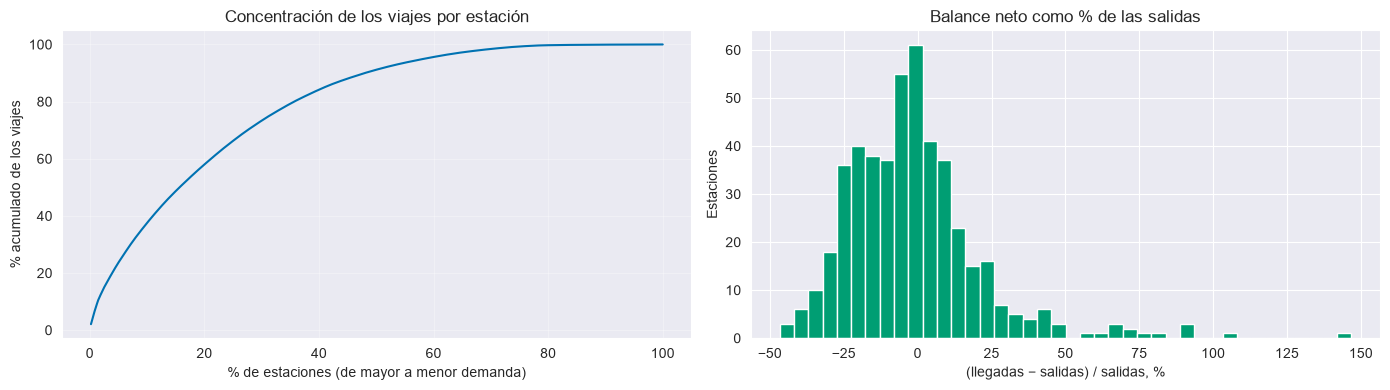

In [20]:
# Concentración de la demanda y distribución del balance neto
fig, ejes = plt.subplots(1, 2, figsize=(14, 4))

acumulado = orden.cumsum() / orden.sum() * 100
ejes[0].plot(np.arange(1, len(acumulado) + 1) / len(acumulado) * 100, acumulado.to_numpy(), color=AZUL)
ejes[0].set_title("Concentración de los viajes por estación")
ejes[0].set_xlabel("% de estaciones (de mayor a menor demanda)")
ejes[0].set_ylabel("% acumulado de los viajes")
ejes[0].grid(alpha=0.3)

estaciones["neto_%"].plot.hist(bins=40, ax=ejes[1], color=VERDE)
ejes[1].set_title("Balance neto como % de las salidas")
ejes[1].set_xlabel("(llegadas − salidas) / salidas, %")
ejes[1].set_ylabel("Estaciones")

plt.tight_layout()
plt.show()

In [21]:
# Estaciones con mayor desbalance neto y relación entre demanda y capacidad
con_capacidad = estaciones[estaciones["dpcapacity"] > 0]
print("Mayor acumulación de bicis (neto positivo):")
display(estaciones.sort_values("neto", ascending=False).head(5)[["name", "salidas", "llegadas", "neto", "neto_%"]])
print("Mayor pérdida de bicis (neto negativo):")
display(estaciones.sort_values("neto").head(5)[["name", "salidas", "llegadas", "neto", "neto_%"]])

correlacion = con_capacidad["salidas"].corr(con_capacidad["dpcapacity"], method="spearman")
print(f"Correlación de Spearman entre salidas y capacidad: {correlacion:.2f}")
print(f"Estaciones con |neto| mayor al 10% de sus salidas: {int((estaciones['neto_%'].abs() > 10).sum())}")

Mayor acumulación de bicis (neto positivo):


,name,salidas,llegadas,neto,neto_%
51,(GDL-049) Lopez Cotilla / Penitenciaría,552081,697952,145871,26.4
34,(GDL-032) C. Degollado / Av. Miguel Hidalgo,204180,269400,65220,31.9
35,(GDL-033) Av. Hidalgo / C. Pedro Loza,397545,454098,56553,14.2
260,(GDL-187) Av. 16 de Septiembre / C. Priscilia,241443,295689,54246,22.5
56,(GDL-054) Av. Juárez / Calz. Independencia,190409,236293,45884,24.1


Mayor pérdida de bicis (neto negativo):


,name,salidas,llegadas,neto,neto_%
194,(GDL-127) Av. Vallarta / Av. de Los Arcos,255281,159743,-95538,-37.4
196,(GDL-129) C. Lope de Vega / Av. Vallarta,163979,131350,-32629,-19.9
197,(GDL-130) C. J. Ruíz de Alarcón / Av Vallarta,111618,82758,-28860,-25.9
11,(GDL-009) Calz. Federalismo/ C. J. Angulo,392767,364377,-28390,-7.2
195,(GDL-128) Av. Morelos / C. Emilio Castelar,93574,65321,-28253,-30.2


Correlación de Spearman entre salidas y capacidad: -0.02
Estaciones con |neto| mayor al 10% de sus salidas: 273


**Observaciones de la demanda y el balance por estación:**
- **Concentración:** 475 estaciones con viajes; la mediana es 30,597 salidas por estación y el máximo 552,081 (GDL-049 Lopez Cotilla / Penitenciaría, capacidad 39). El 10 % de las estaciones (48) concentra el 37.8 % de los viajes. 74 estaciones (15.6 %) tienen menos de 1,000 salidas en seis años y nueve meses; probablemente sean estaciones nuevas o retiradas, lo que se debe verificar con su primera y última fecha activa antes de decidir su tratamiento.
- **Balance neto:** 273 de las 475 estaciones (57.5 %) tienen un balance mayor al 10 % de sus salidas, positivo o negativo, acumulado en el periodo. Las que más acumulan bicicletas están en el centro (GDL-049 con +145,871, +26.4 %; GDL-032 Degollado/Hidalgo con +31.9 %). Las que más pierden están sobre Av. Vallarta (GDL-127 con −95,538, −37.4 %; GDL-129, GDL-130 y GDL-128 con −19.9 % a −30.2 %). Es un patrón geográfico consistente, y es justo el desbalance que el rebalanceo debe compensar. El EDA no observa los traslados que ya hace la operación.
- **Capacidad:** la correlación de Spearman entre salidas y capacidad es −0.02: la capacidad instalada no sigue a la demanda. Hay estaciones de capacidad 15 con 397,545 salidas (GDL-033) y otras de capacidad 39 con 552,081. Un mismo desbalance absoluto pesa muy distinto según la estación.
- **Implicación para P1, P2 y P3:** en P1 el error debe reportarse por estación y no solo en total, porque el 10 % de las estaciones domina el volumen. En P2 el balance debe normalizarse por capacidad (`neto_sobre_capacidad`), no usarse en valores absolutos. En P3, el desbalance y la ubicación son señales de agrupamiento y las estaciones con menos de 1,000 salidas deben filtrarse antes de agrupar.

## Paso 3: Limpieza, partición y preprocesamiento

En este paso se convierten los hallazgos del EDA en reglas explícitas, se separan los datos en conjuntos temporales y se dejan listas las tablas para el modelado. Se sigue el orden del pipeline (`references/pipeline-ml.md`):
1. **Limpieza** (3.1 y 3.2): cada regla se justifica con una cifra del EDA y registra cuántos registros retira.
2. **Partición** (3.3): temporal, con una brecha de 24 horas entre conjuntos para que ninguna etiqueta use datos del conjunto siguiente.
3. **Preprocesamiento** (3.4): tabla de estaciones calculada solo con entrenamiento y tabla de demanda por estación-hora, la base de P1 y P2.

**Principio:** nada de lo que se calcule con validación o prueba puede influir en una decisión de limpieza o de preprocesamiento.

### 3.1 Decisiones de limpieza

| Hallazgo (sección 2.2) | Decisión | Justificación |
|---|---|---|
| 758 filas completas repetidas | **Eliminar** (conservar una) | Son idénticas en todas las columnas; no hay conflictos que resolver |
| 3,961 viajes con origen o destino sin nomenclatura | **Excluir** | Sin capacidad ni ubicación no se pueden usar en P2 ni P3; son el 0.015 % |
| 53,581 viajes con duración cero | **Excluir** | Probable desbloqueo fallido: no es un traslado. Su sensibilidad se medirá al modelar |
| 157 viajes de más de 24 h (máximo 469 h) | **Excluir** | La hora de llegada no es real; distorsionaría el balance neto de P2 |
| Viajes de 1 a 24 h | **Conservar** | El 99.9 % dura menos de 59 min; la cola moderada es plausible y no afecta los conteos |
| Nulos en `genero` (0.51 %) y `anio_de_nacimiento` (0.13 %) | **No imputar; descartar las columnas** | Ninguna pregunta las usa y son datos personales (minimización) |
| `usuario_id` | **Descartar** | Dato personal y las preguntas son por estación, no por persona |
| Años de nacimiento imposibles | **Sin acción** | Se descartan junto con la columna |
| Hueco 2023-04 y 2023-05 | **No imputar; excluir esas horas de la tabla de demanda** | Rellenar con ceros inventaría una demanda nula que no ocurrió |
| Horas 1:00 a 4:59 sin servicio | **Excluir de la tabla de demanda** | Son horas cerradas, no demanda cero medida |
| 4 estaciones con capacidad 0 | **Conservar los viajes; marcar la estación** | Sirven para P1; se excluyen solo de P2 |

In [22]:
# Aplicación de las reglas de limpieza en orden; cada paso registra cuántos registros retira
COLUMNAS_MODELADO = ["viaje_id", "inicio_del_viaje", "fin_del_viaje", "origen_id", "destino_id",
                     "duracion_min", "periodo_archivo"]
DURACION_MAXIMA_MIN = 24 * 60

limpios = viajes[COLUMNAS_MODELADO]   # usuario_id, genero y anio_de_nacimiento no pasan
bitacora = [{"regla": "Registros iniciales", "retirados": 0, "quedan": len(limpios)}]

def aplicar(regla, datos, conservar):
    """Conserva los registros que cumplen la regla y anota cuántos se retiran."""
    resultado = datos[conservar]
    bitacora.append({"regla": regla, "retirados": len(datos) - len(resultado), "quedan": len(resultado)})
    return resultado

limpios = aplicar("Viajes con viaje_id repetido (filas idénticas)", limpios, ~limpios["viaje_id"].duplicated())
limpios = aplicar("Origen o destino sin nomenclatura", limpios,
                  limpios["origen_id"].isin(ids_nomenclatura) & limpios["destino_id"].isin(ids_nomenclatura))
limpios = aplicar("Duración cero", limpios, limpios["duracion_min"] > 0)
limpios = aplicar("Duración mayor a 24 h", limpios, limpios["duracion_min"] <= DURACION_MAXIMA_MIN)
limpios = limpios.reset_index(drop=True)

bitacora = pd.DataFrame(bitacora)
bitacora["% retirado"] = (bitacora["retirados"] / bitacora.loc[0, "quedan"] * 100).round(3)
bitacora

,regla,retirados,quedan,% retirado
0,Registros iniciales,0,26389162,0.000
1,Viajes con viaje_id repetido (filas idénticas),758,26388404,0.003
2,Origen o destino sin nomenclatura,3961,26384443,0.015
3,Duración cero,53580,26330863,0.203
4,Duración mayor a 24 h,157,26330706,0.001


In [23]:
# Validación de la limpieza: ninguna regla debe quedar sin cumplirse
assert limpios["viaje_id"].is_unique, "quedan viaje_id repetidos"
assert limpios["origen_id"].isin(ids_nomenclatura).all() and limpios["destino_id"].isin(ids_nomenclatura).all()
assert limpios["duracion_min"].between(0, DURACION_MAXIMA_MIN, inclusive="right").all()
assert limpios[["inicio_del_viaje", "fin_del_viaje", "origen_id", "destino_id"]].notna().all().all()

retirados = len(viajes) - len(limpios)
print(f"Registros originales : {len(viajes):,}")
print(f"Registros limpios    : {len(limpios):,}")
print(f"Retirados            : {retirados:,} ({retirados / len(viajes):.3%})")

# Guardado del dataset limpio para los siguientes notebooks (CCDS: datos intermedios)
ruta_limpios = RUTA_INTERMEDIOS / f"viajes_limpios_{MES_INICIO}_{MES_FIN}.parquet"
limpios.to_parquet(ruta_limpios, index=False)
print(f"Archivo: {ruta_limpios.name} ({ruta_limpios.stat().st_size / 1024**2:.1f} MB)")

# Se libera la memoria del dataset sin limpiar; el resto del notebook usa solo `limpios`
del viajes

Registros originales : 26,389,162
Registros limpios    : 26,330,706
Retirados            : 58,456 (0.222%)
Archivo: viajes_limpios_2020-01_2026-09.parquet (518.9 MB)


**Observaciones de la limpieza:**
- **Registros retirados:** 58,456 de 26,389,162 (0.222 %); quedan 26,330,706. Por regla: 758 duplicados (0.003 %), 3,961 sin nomenclatura (0.015 %), 53,580 de duración cero (0.203 %) y 157 de más de 24 h (0.001 %). La duración cero cuenta 53,580 y no 53,581 como en 2.2 porque un viaje ya había salido por una regla anterior; el log es secuencial.
- **Regla con más impacto:** la duración cero explica el 91.7 % de lo retirado. Es la única decisión con un costo apreciable, y es la que se someterá a prueba de sensibilidad en el modelado (con y sin esos viajes).
- **Validación:** las cuatro verificaciones pasan (`viaje_id` único, estaciones con nomenclatura, duración en (0, 24 h] y sin nulos en fechas ni estaciones). El dataset limpio se guardó en `data/interim/viajes_limpios_2020-01_2026-09.parquet` (518.9 MB).
- **Lo que no se hizo:** no se imputó ningún valor, no se recortaron duraciones entre 1 y 24 h y no se rellenó el hueco de 2023-04 y 2023-05. `usuario_id`, `genero` y `anio_de_nacimiento` no pasan al dataset limpio.

### 3.2 Partición temporal

La partición es **temporal**: el entrenamiento ocupa el periodo más antiguo, la validación el siguiente y la prueba el más reciente. Una partición aleatoria mezclaría días vecinos entre conjuntos y el modelo vería, durante el entrenamiento, información de los días que luego debería predecir.

| Conjunto | Periodo | Para qué se usa |
|---|---|---|
| **train** | 2020-01-01 a 2024-09-30 | Ajustar modelos y calcular todo parámetro de preprocesamiento |
| **valid** | 2024-10-01 a 2025-09-30 | Elegir hiperparámetros y umbrales |
| **test** | 2025-10-01 a 2026-09-30 | Evaluación final, una sola vez |

Los bloques de validación y prueba duran 12 meses para que cada uno cubra las cuatro estaciones del año. Las **24 horas previas a cada frontera** quedan en un conjunto `brecha` que no se usa: una etiqueta de P1 mira hasta 24 horas adelante, y sin la brecha los últimos registros de un conjunto tendrían etiquetas calculadas con datos del siguiente.

In [24]:
# Fronteras de la partición temporal y brecha entre conjuntos
FRONTERA_VALID = pd.Timestamp("2024-10-01")
FRONTERA_TEST = pd.Timestamp("2025-10-01")
BRECHA = pd.Timedelta(hours=24)

def asignar_particion(marcas_de_tiempo):
    """Regresa train, valid, test o brecha según el instante de inicio."""
    condiciones = [marcas_de_tiempo < FRONTERA_VALID - BRECHA,
                   marcas_de_tiempo < FRONTERA_VALID,
                   marcas_de_tiempo < FRONTERA_TEST - BRECHA,
                   marcas_de_tiempo < FRONTERA_TEST]
    return pd.Series(np.select(condiciones, ["train", "brecha", "valid", "brecha"], default="test"),
                     index=marcas_de_tiempo.index).astype(
        pd.CategoricalDtype(["train", "valid", "test", "brecha"]))

limpios["particion"] = asignar_particion(limpios["inicio_del_viaje"])

resumen_particion = limpios.groupby("particion", observed=True).agg(
    viajes=("viaje_id", "size"),
    primer_viaje=("inicio_del_viaje", "min"),
    ultimo_viaje=("inicio_del_viaje", "max"),
)
resumen_particion["% de los viajes"] = (resumen_particion["viajes"] / len(limpios) * 100).round(1)
resumen_particion

,viajes,primer_viaje,ultimo_viaje,% de los viajes
particion,,,,
train,17291138,2020-01-01 06:02:20,2024-09-29 23:59:00,65.7
valid,4520744,2024-10-01 00:00:00,2025-09-29 23:59:17,17.2
test,4489362,2025-10-01 00:00:26,2026-09-30 23:59:48,17.0
brecha,29462,2024-09-30 00:00:00,2025-09-30 23:59:53,0.1


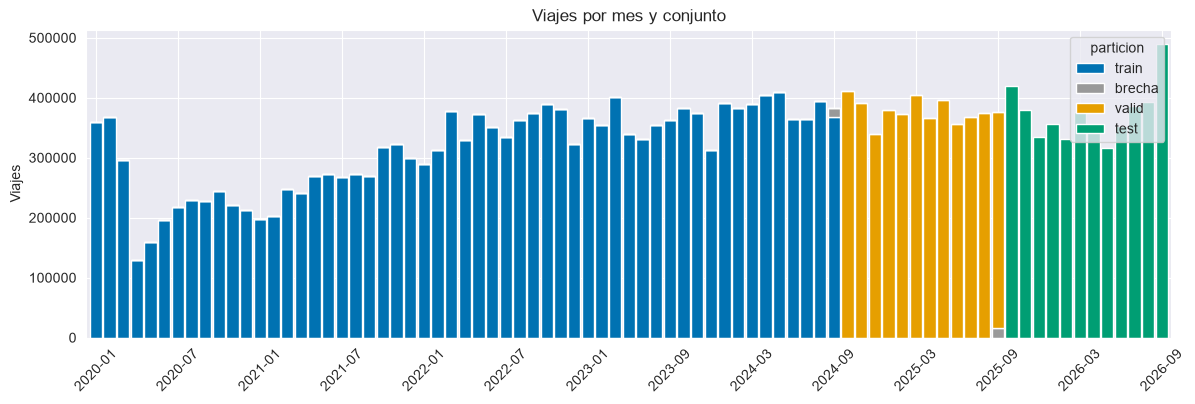

In [25]:
# Validación de la partición: orden temporal estricto y sin superposición
por_conjunto = limpios.groupby("particion", observed=True)["inicio_del_viaje"].agg(["min", "max"])
assert por_conjunto.loc["train", "max"] < por_conjunto.loc["valid", "min"]
assert por_conjunto.loc["valid", "max"] < por_conjunto.loc["test", "min"]
assert (limpios["particion"] != "brecha").sum() + (limpios["particion"] == "brecha").sum() == len(limpios)

# Viajes por mes, coloreados por conjunto
mensual_particion = (limpios.groupby(["periodo_archivo", "particion"], observed=True).size()
                     .unstack(fill_value=0)[["train", "brecha", "valid", "test"]])
mensual_particion.index = pd.PeriodIndex(mensual_particion.index.astype(str), freq="M").to_timestamp()

ax = mensual_particion.plot.bar(stacked=True, figsize=(14, 4), width=0.9,
                                color=[AZUL, "#999999", NARANJA, VERDE])
ax.set_xticks(range(0, len(mensual_particion), 6))
ax.set_xticklabels([m.strftime("%Y-%m") for m in mensual_particion.index[::6]], rotation=45)
ax.set_title("Viajes por mes y conjunto")
ax.set_xlabel("")
ax.set_ylabel("Viajes")
plt.show()

**Observaciones de la partición:**
- **Tamaño de los conjuntos:** train 17,291,138 viajes (65.7 %), valid 4,520,744 (17.2 %) y test 4,489,362 (17.0 %). Valid y test son casi del mismo tamaño, lo que hace comparables sus métricas.
- **Brecha:** 29,462 viajes (0.1 %) quedan fuera, las 24 horas previas a 2024-10-01 y a 2025-10-01. El costo en datos es despreciable.
- **Cobertura estacional:** valid (2024-10 a 2025-09) y test (2025-10 a 2026-09) cubren cada uno 12 meses completos, así que incluyen las cuatro estaciones del año. Train abarca 2020-01 a 2024-09 con el hueco de 2023-04 y 2023-05.
- **Riesgo:** train contiene el choque de la pandemia (2020) y test no; la diferencia de régimen puede mejorar o empeorar el error por razones ajenas al modelo. Además, 2026-09 (490,056 viajes, el máximo de la serie) cae en test y sigue sin verificarse.

### 3.3 Preprocesamiento

Se preparan dos tablas que reutilizarán los modelos:
- **Tabla de estaciones** (`estaciones_train`): capacidad, ubicación y actividad, calculada **solo con el entrenamiento**. Es la que usará P3 y la que define el nivel base de cada estación en P1.
- **Demanda por estación-hora** (`demanda_estacion_hora`): viajes que inician en cada estación y hora, con tres reglas para no inventar datos:
  1. Los ceros comienzan en la **primera hora activa** de cada estación; antes de abrir no hay demanda cero, no hay estación.
  2. Se excluyen las horas de **1:00 a 4:59**, en las que el servicio no opera.
  3. Se excluyen las horas de los meses **sin archivo** (2023-04 y 2023-05).

In [26]:
# Tabla de estaciones calculada solo con el conjunto de entrenamiento
entrenamiento = limpios[limpios["particion"] == "train"]
actividad = pd.DataFrame({
    "salidas_train": entrenamiento["origen_id"].value_counts(),
    "llegadas_train": entrenamiento["destino_id"].value_counts(),
})
estaciones_train = (nomenclatura.set_index("id")[["name", "latitude", "longitude", "dpcapacity"]]
                    .join(actividad).fillna({"salidas_train": 0, "llegadas_train": 0}))
estaciones_train[["salidas_train", "llegadas_train"]] = estaciones_train[["salidas_train", "llegadas_train"]].astype(int)
estaciones_train["neto_train"] = estaciones_train["llegadas_train"] - estaciones_train["salidas_train"]
estaciones_train["capacidad_cero"] = estaciones_train["dpcapacity"] == 0
estaciones_train["activa_en_train"] = estaciones_train["salidas_train"] > 0

print("Estaciones en la nomenclatura          :", len(estaciones_train))
print("Con salidas en entrenamiento           :", int(estaciones_train["activa_en_train"].sum()))
print("Sin viajes en entrenamiento (nuevas)   :", int((~estaciones_train["activa_en_train"]).sum()))
print("Con capacidad 0 (fuera de P2)          :", int(estaciones_train["capacidad_cero"].sum()))
print("Con menos de 1,000 salidas en train    :", int((estaciones_train["salidas_train"] < 1000).sum()))

estaciones_train.to_parquet(RUTA_PROCESADOS / "estaciones_train.parquet")
estaciones_train.sort_values("salidas_train", ascending=False).head()

Estaciones en la nomenclatura          : 484
Con salidas en entrenamiento           : 363
Sin viajes en entrenamiento (nuevas)   : 121
Con capacidad 0 (fuera de P2)          : 4
Con menos de 1,000 salidas en train    : 122


,name,latitude,longitude,dpcapacity,salidas_train,llegadas_train,neto_train,capacidad_cero,activa_en_train
id,,,,,,,,,
51,(GDL-049) Lopez Cotilla / Penitenciaría,20.674140,-103.355535,39,365771,468201,102430,False,True
271,(GDL-198) Av. Alcalde / C. Hospital,20.685040,-103.347960,31,266503,257100,-9403,False,True
11,(GDL-009) Calz. Federalismo/ C. J. Angulo,20.682077,-103.353835,23,260857,242096,-18761,False,True
35,(GDL-033) Av. Hidalgo / C. Pedro Loza,20.677419,-103.347983,15,248776,277997,29221,False,True
52,(GDL-050) C.Pedro Moreno /Federalismo,20.675746,-103.354579,23,238779,237667,-1112,False,True


In [27]:
# Demanda por estación-hora: conteo de viajes y rejilla completa desde la primera hora activa
limpios["hora_inicio"] = limpios["inicio_del_viaje"].dt.floor("h")
demanda = (limpios.groupby(["origen_id", "hora_inicio"], observed=True).size()
           .rename("viajes").reset_index())

# Horas válidas: dentro del rango, con servicio y en meses con archivo
ultima_hora = pd.Timestamp(MES_FIN + "-01") + pd.offsets.MonthEnd(0) + pd.Timedelta(hours=23)
horas = pd.date_range(f"{MES_INICIO}-01", ultima_hora, freq="h")
meses_hora = horas.strftime("%Y-%m")
horas_validas = horas[~horas.hour.isin([1, 2, 3, 4]) & ~np.isin(meses_hora, MESES_SIN_PUBLICAR)]

# Rejilla: para cada estación, todas las horas válidas desde su primera hora con viajes
primera_hora = demanda.groupby("origen_id")["hora_inicio"].min()
ids, instantes = [], []
for estacion, primera in primera_hora.items():
    posicion = horas_validas.searchsorted(primera)
    ids.append(np.full(len(horas_validas) - posicion, estacion, dtype="int32"))
    instantes.append(horas_validas[posicion:].to_numpy())
rejilla = pd.DataFrame({"origen_id": np.concatenate(ids), "hora_inicio": np.concatenate(instantes)})

demanda_estacion_hora = rejilla.merge(demanda.astype({"origen_id": "int32"}), on=["origen_id", "hora_inicio"], how="left")
demanda_estacion_hora["viajes"] = demanda_estacion_hora["viajes"].fillna(0).astype("int16")
demanda_estacion_hora["particion"] = asignar_particion(demanda_estacion_hora["hora_inicio"])

excluidos = int(len(demanda) - demanda.merge(rejilla, on=["origen_id", "hora_inicio"]).shape[0])
print(f"Estaciones en la rejilla        : {demanda_estacion_hora['origen_id'].nunique()}")
print(f"Filas estación-hora             : {len(demanda_estacion_hora):,}")
print(f"Horas sin viajes (ceros)        : {(demanda_estacion_hora['viajes'] == 0).mean():.1%}")
print(f"Estación-horas con viajes fuera de la rejilla: {excluidos:,}")
print(f"Viajes totales en la rejilla    : {int(demanda_estacion_hora['viajes'].sum()):,}")
print(f"Viajes limpios                  : {len(limpios):,}")

demanda_estacion_hora.to_parquet(RUTA_PROCESADOS / "demanda_estacion_hora.parquet", index=False)
demanda_estacion_hora.groupby("particion", observed=True)["viajes"].describe().round(2)

Estaciones en la rejilla        : 472
Filas estación-hora             : 15,812,633
Horas sin viajes (ceros)        : 44.3%
Estación-horas con viajes fuera de la rejilla: 152
Viajes totales en la rejilla    : 26,330,548
Viajes limpios                  : 26,330,706


,count,mean,std,min,25%,50%,75%,max
particion,,,,,,,,
train,10199442.0,1.70,2.64,0.0,0.0,1.0,2.0,91.0
valid,2690762.0,1.68,2.68,0.0,0.0,1.0,2.0,207.0
test,2907729.0,1.54,2.66,0.0,0.0,1.0,2.0,149.0
brecha,14700.0,2.00,2.94,0.0,0.0,1.0,3.0,59.0


**Observaciones del preprocesamiento:**
- **Estaciones:** de las 484 de la nomenclatura, 363 tienen viajes en entrenamiento y 121 no: 109 aparecen después de 2024-09 (todas con viajes en test) y 12 no registran ningún viaje en todo el periodo. Cuatro tienen capacidad 0 y 122 tienen menos de 1,000 salidas en train.
- **Demanda estación-hora:** 15,812,633 filas para 472 estaciones, con 26,330,548 viajes. Se excluyeron 158 viajes (152 estación-horas) que caen en horas de 1:00 a 4:59. La rejilla arranca en la primera hora activa de cada estación, por lo que ninguna estación tiene ceros antes de existir.
- **Dispersión:** el 44.3 % de las estación-horas no tiene viajes; la mediana es 1 y la media 1.70 en train. Es una variable de conteo con muchos ceros, lo que respalda el objetivo Poisson y obliga a comparar contra el baseline en MAE, porque predecir cero ya acierta casi la mitad de las veces. Se revisará el máximo de 207 viajes en una estación-hora de validación.
- **Estaciones nuevas (hallazgo):** 109 estaciones no tienen historia en train y aparecen en test, donde generan 168,382 viajes (3.8 %). Esto baja la media de test (1.54 contra 1.70) y sube su proporción de ceros (46.5 % contra 43.9 %) sin que la demanda haya cambiado. Para ellas `demanda_media_estacion` no existe.
- **Pendiente:** definir el tratamiento de las estaciones nuevas en P1: un indicador `estacion_nueva`, un nivel base tomado de la capacidad o de la zona y una métrica que las reporte aparte. Para P3, las estaciones sin historia en train quedan fuera del agrupamiento y se asignan después al grupo más cercano.